# 5. házi feladat: saját regressziós modell, King County házárak

**Adat:** King County házeladások, 2014-05 – 2015-05 (OpenML 42092, house_sales, CC0).

**Felépítés:** kérdés és mutató, EDA, tisztítás, **zárolt teszt**, alapmodellek, mutatók, **diagnosztika**, egy visszacsatolási kör, majd a záró teszt egyszer, végül a korlátok.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import NearestNeighbors
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 100

## 1. A kérdés és a célváltozó

**A jósolt szám** egy King County-i ház **eladási ára (USD)**, a ház jellemzőiből (méret, állapot, minőség, hely, kor), az eladás előtt. A felhasználó egy **bank, amely jelzálog-fedezetet értékel**. **A fölülbecslés a drágább hiba:** túl magas fedezeti érték esetén a bank túl nagy hitelt ad, és nemfizetéskor a ház eladásából nem jön vissza a pénze. Az alulbecslés is költség (elmaradó ügyfél), de kisebb. Ezért a hiba nagysága mellett az **irányát** is mérem: a *jósolt/tényleges* összeg 1 fölött rendszeres fölülbecslést jelent.

**Fő mutató: RMSLE.** A hiba arányos: egy 100 ezres tévedés egy 250 ezres háznál 40%, egy 2,5 milliósnál 4%, és a banknak a relatív kockázat számít. Az RMSLE a log-skálán mér, ezért minden ház arányosan számít. **Kiegészítő mutatók:** RMSE és MAE (USD-ben, könnyen kommunikálható; az RMSE-t a drága házak uralják), WAPE (a teljes érték hány százalékát tévesztjük), R² (csak tájékoztató, az átlaghoz mér), és a jósolt/tényleges arány.

**Előre rögzített szabály:** a modellek közül a **legkisebb CV-RMSLE**-jű megy a záró tesztre. A teszthalmazon semmit nem választok.

## 2. Betöltés és első ellenőrzés

In [2]:
# Adatforrás: OpenML 42092 (house_sales); kc_house_data.csv = ugyanennek az adatnak a helyi másolata
if os.path.exists("kc_house_data.csv"):
    raw = pd.read_csv("kc_house_data.csv", dtype={"date": str})
    forras = "kc_house_data.csv"
else:
    raw = fetch_openml(data_id=42092, as_frame=True).frame
    forras = "OpenML 42092"

df = raw.drop(columns=["id"], errors="ignore").copy()   # az 'id' csak a Kaggle-fájlban van; nem jellemző
for c in df.columns:                                     # az OpenML néhány oszlopot 'category'-ként ad
    if c != "date":
        df[c] = pd.to_numeric(df[c].astype(str), errors="coerce")
assert df.drop(columns="date").isna().sum().sum() == 0
df["date"] = pd.to_datetime(df["date"].astype(str).str[:8], format="%Y%m%d")   # '20141013T000000' -> dátum

print("Forrás:", forras)
print("Sor × oszlop:", df.shape, "| hiányzó érték:", int(df.isna().sum().sum()))
print("Eladások:", df["date"].min().date(), "–", df["date"].max().date())
p = df["price"]
print(f"Ár: átlag {p.mean():,.0f}, medián {p.median():,.0f}, max {p.max():,.0f} USD; 1 M fölött: {(p > 1e6).mean():.1%}")
print(f"Ferdeség: nyers ár {p.skew():.2f}, log(ár) {np.log(p).skew():.2f}")
print("Irányítószámok:", df["zipcode"].nunique())
df.head()

Forrás: kc_house_data.csv
Sor × oszlop: (21613, 20) | hiányzó érték: 0
Eladások: 2014-05-02 – 2015-05-27
Ár: átlag 540,088, medián 450,000, max 7,700,000 USD; 1 M fölött: 6.8%
Ferdeség: nyers ár 4.02, log(ár) 0.43
Irányítószámok: 70


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,"221,900.0000",3,1.0000,1180,5650,1.0000,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.2570,1340,5650
1,2014-12-09,"538,000.0000",3,2.2500,2570,7242,2.0000,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.3190,1690,7639
2,2015-02-25,"180,000.0000",2,1.0000,770,10000,1.0000,0,0,3,6,770,0,1933,0,98028,47.7379,-122.2330,2720,8062
3,2014-12-09,"604,000.0000",4,3.0000,1960,5000,1.0000,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.3930,1360,5000
4,2015-02-18,"510,000.0000",3,2.0000,1680,8080,1.0000,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.0450,1800,7503


## 3. EDA

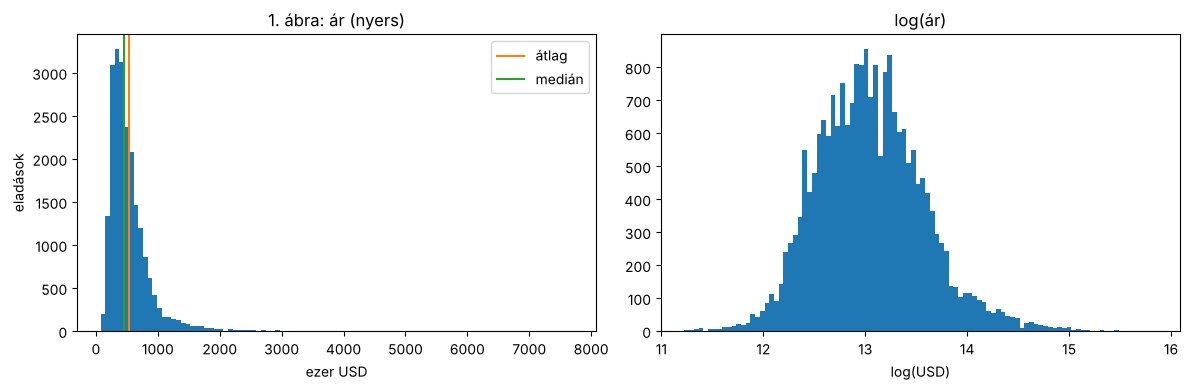

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["price"] / 1000, bins=100)
ax[0].axvline(p.mean() / 1000, color="C1", label="átlag"); ax[0].axvline(p.median() / 1000, color="C2", label="medián")
ax[0].set(title="1. ábra: ár (nyers)", xlabel="ezer USD", ylabel="eladások"); ax[0].legend()
ax[1].hist(np.log(df["price"]), bins=100)
ax[1].set(title="log(ár)", xlabel="log(USD)")
plt.tight_layout(); plt.show()

**Mit látok:** az ár erősen **jobbra elnyúló**: az átlag (540 ezer) jóval a medián (450 ezer) fölött van, a ferdeség 4,02, a maximum 7,7 millió. Log után a ferdeség 0,43, az eloszlás közel szimmetrikus.
**Mit kezdek vele:** a modellek a **log(ár)**-at jósolják (az átlag és a zip-medián alapmodell kivételével, mert ezek közvetlenül USD-t adnak). Két okból: (1) a hibák arányosak lesznek, ahogy az órán a „tölcsér” megoldásánál láttuk; (2) a fő mutatóm, az RMSLE, ugyanezen a skálán mér. Az ára a visszaalakítás torzítása, ezt a 6. pontban kimutatom.

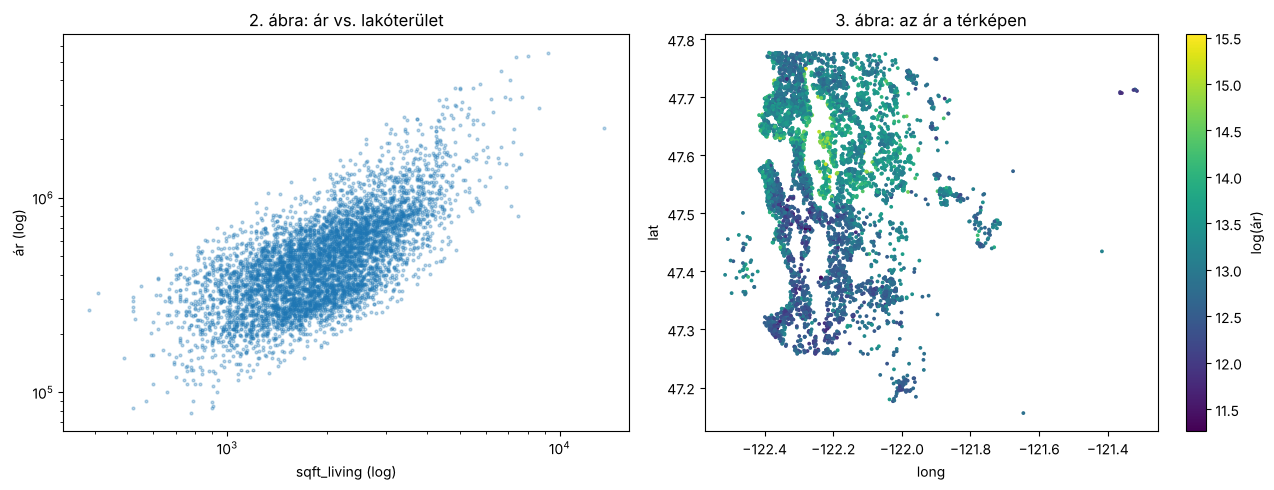

Korreláció, log(ár) ~ log(sqft_living): 0.675


In [4]:
s = df.sample(6000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(s["sqft_living"], s["price"], s=4, alpha=0.3)
ax[0].set(xscale="log", yscale="log", xlabel="sqft_living (log)", ylabel="ár (log)", title="2. ábra: ár vs. lakóterület")
sc = ax[1].scatter(s["long"], s["lat"], c=np.log(s["price"]), s=3, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label="log(ár)")
ax[1].set(xlabel="long", ylabel="lat", title="3. ábra: az ár a térképen")
plt.tight_layout(); plt.show()
print("Korreláció, log(ár) ~ log(sqft_living):", round(np.corrcoef(np.log(df["price"]), np.log(df["sqft_living"]))[0, 1], 3))

**Mit látok:** (a) log-log skálán az ár és a lakóterület kapcsolata közel **egyenes** (korreláció 0,675). Ez jó hír a log-célú lineáris modellnek: a log-területet érdemes jellemzőnek adni. (b) A térképen az ár **foltokban** változik: a tó két partja (Seattle északi és nyugati része, Bellevue, Mercer Island) drága, a déli és a keleti, vidéki rész olcsóbb.
**Következmény:** a hely a legfontosabb, de nem egyenes vonalban hat. Ezért a lineáris modellben az irányítószám **dummykként** szerepel, a fák pedig a `lat`/`long`-ot kapják. A foltos szerkezet a 8. pont jellemzőinek is a kiindulópontja.

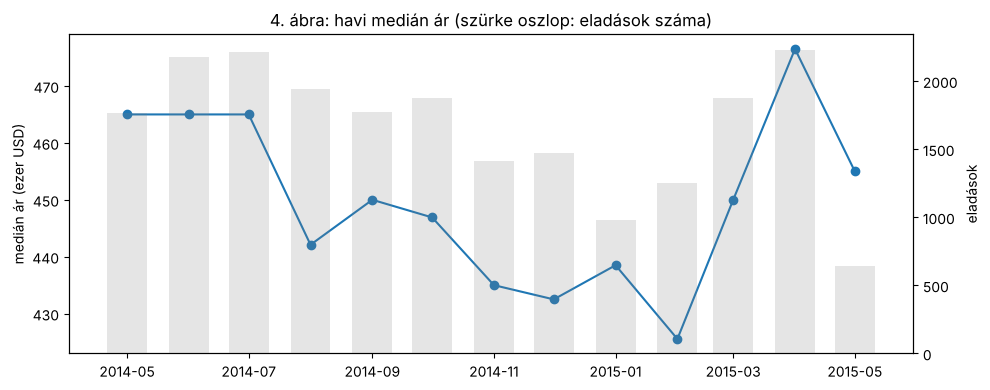

date,2014-05-01,2014-06-01,2014-07-01,2014-08-01,2014-09-01,2014-10-01,2014-11-01,2014-12-01,2015-01-01,2015-02-01,2015-03-01,2015-04-01,2015-05-01
median,"465,000.0000","465,000.0000","465,000.0000","442,100.0000","450,000.0000","446,900.0000","435,000.0000","432,500.0000","438,500.0000","425,545.0000","450,000.0000","476,500.0000","455,000.0000"
count,"1,768.0000","2,180.0000","2,211.0000","1,940.0000","1,774.0000","1,878.0000","1,411.0000","1,471.0000",978.0000,"1,250.0000","1,875.0000","2,231.0000",646.0000


In [5]:
m = df.set_index("date").resample("MS")["price"].agg(["median", "count"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m.index, m["median"] / 1000, marker="o")
ax.set(ylabel="medián ár (ezer USD)", title="4. ábra: havi medián ár (szürke oszlop: eladások száma)")
ax2 = ax.twinx(); ax2.bar(m.index, m["count"], width=20, alpha=0.2, color="gray"); ax2.set_ylabel("eladások")
plt.tight_layout(); plt.show()
m.T

**Mit látok:** erős **szezonalitás** van. A medián ár 2014 májusa és júliusa között 465 ezer, télen 425–438 ezer (februárban 425,5 ezer), 2015 tavaszán újra 450–476,5 ezer (áprilisban). 2015 májusa csak részleges hónap (646 eladás).
**Következmény a vágásra:** ha időrendben vágok, a teszt (2015 tavasza) **főszezon**, a tanító adat viszont téli mélyponttal ér véget. A fa a tanító tartományán kívül nem extrapolál (órai „sodródás”). Erre a tesztnél külön figyelek (havonta jósolt/tényleges).

## 4. Tisztítás

Minden döntés csak a **jellemzőkre** támaszkodik, a célváltozóra nem. Egy új háznál is ugyanígy járnék el, ezért nem okoz szivárgást, hogy a split előtt történik.

In [6]:
cols = ["date", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "grade", "yr_built", "zipcode"]
print(df["bedrooms"].value_counts().sort_index().to_dict())
df.loc[(df["bedrooms"] >= 10) | (df["bedrooms"] == 0), cols].sort_values("bedrooms")

{0: 13, 1: 199, 2: 2760, 3: 9824, 4: 6882, 5: 1601, 6: 272, 7: 38, 8: 13, 9: 6, 10: 3, 11: 1, 33: 1}


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,yr_built,zipcode
875,2014-06-12,"1,095,000.0000",0,0.0000,3064,4764,7,1990,98102
3119,2015-02-05,"380,000.0000",0,0.0000,1470,979,8,2006,98133
3467,2014-08-05,"288,000.0000",0,1.5000,1430,1650,7,1999,98125
4868,2014-10-02,"228,000.0000",0,1.0000,390,5900,4,1953,98118
6994,2014-06-24,"1,295,650.0000",0,0.0000,4810,28008,12,1990,98053
8477,2014-11-17,"339,950.0000",0,2.5000,2290,8319,8,1985,98042
8484,2014-09-25,"240,000.0000",0,2.5000,1810,5669,7,2003,98038
9773,2015-04-29,"355,000.0000",0,0.0000,2460,8049,8,1990,98031
18379,2014-10-29,"265,000.0000",0,0.7500,384,213444,4,2003,98070
9854,2014-12-23,"235,000.0000",0,0.0000,1470,4800,7,1996,98065


In [7]:
# Döntés 1: a 33 hálószoba elírás (lásd a lenti indoklást) -> 3. A 0, 10 és 11 hálószobás sorok maradnak.
print("A 33-as ház:", df.loc[df["bedrooms"] == 33, ["sqft_living", "bathrooms", "price"]].to_dict("records"))
print("3 hálószobás házak medián alapterülete:", df.loc[df["bedrooms"] == 3, "sqft_living"].median())
df.loc[df["bedrooms"] == 33, "bedrooms"] = 3

# Döntés 2: yr_renovated = 0 jelentése „nem újították fel / nincs adat”, nem „0. év”.
print(f"\nyr_renovated == 0: {(df['yr_renovated'] == 0).mean():.1%}")
df["sale_year"] = df["date"].dt.year
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
last_work = np.where(df["yr_renovated"] > 0, df["yr_renovated"], df["yr_built"])
df["age"] = (df["sale_year"] - df["yr_built"]).clip(lower=0)          # kor az eladáskor (-1: az építés éve előtt eladva)
df["yrs_since_work"] = (df["sale_year"] - last_work).clip(lower=0)    # évek az építés vagy a felújítás óta
df = df.drop(columns=["yr_renovated", "sale_year"])

# Döntés 3: sqft_living = sqft_above + sqft_basement? Ha igen, a sqft_above felesleges (tökéletes kollinearitás).
ok = (df["sqft_above"] + df["sqft_basement"] == df["sqft_living"]).mean()
print(f"sqft_living == sqft_above + sqft_basement: {ok:.2%}")
if ok == 1.0:
    df = df.drop(columns=["sqft_above"])

# Döntés 4: az irányítószám kategória. A lineáris modellnek szöveg (-> dummyk); a fáknak egy egész kód is megmarad.
df["zip_num"] = df["zipcode"].astype(int)
df["zipcode"] = df["zipcode"].astype(int).astype(str)

# Időjellemzők és log-területek (nem a célból számolódnak, így a split előtt is szivárgásmentesek)
df["month"] = df["date"].dt.month
df["t_days"] = (df["date"] - df["date"].min()).dt.days
for c in ["sqft_living", "sqft_lot", "sqft_living15", "sqft_lot15"]:
    df["log_" + c] = np.log(df[c])

# Ismétlődő ingatlanok
KEY = ["lat", "long", "sqft_living", "sqft_lot", "yr_built", "zipcode"]
df["house_id"] = df.groupby(KEY, sort=False).ngroup()
n_sales = df.groupby("house_id").size()
print(f"Többször eladott házak: {(n_sales > 1).sum()} ház, {n_sales[n_sales > 1].sum()} sor; eladások/ház: {n_sales[n_sales > 1].value_counts().to_dict()}")

A 33-as ház: [{'sqft_living': 1620, 'bathrooms': 1.75, 'price': 640000.0}]
3 hálószobás házak medián alapterülete: 1680.0

yr_renovated == 0: 95.8%


sqft_living == sqft_above + sqft_basement: 100.00%
Többször eladott házak: 195 ház, 392 sor; eladások/ház: {2: 193, 3: 2}


**A tisztítási döntések és indokaik:**

1. **33 hálószoba → 3.** A ház alapterülete 1620 sqft, 1,75 fürdőszobával. A 3 hálószobás házak medián alapterülete 1680 sqft, vagyis pont ilyen. 33 szoba ekkora területen fizikailag lehetetlen, ezért elírásnak veszem.
2. **A 10 és 11 hálószobás házak maradnak.** 2920–4590 sqft-osak, ami nagy, de lehetséges.
3. **A 0 hálószobás sorok (13 db, 0,06%) maradnak.** Többüknél a fürdőszoba is 0, de a terület nagy (pl. 4810 sqft, 1,3 M USD), tehát valószínűleg hiányzó adatot rögzítettek 0-ként. Annyira kevés, hogy nem torzít, a fa pedig külön ágon kezeli. (Ezt a korlátok között is említem.)
4. **`yr_renovated`:** 95,8%-ban 0, ami „nincs felújítás / nincs adat”, nem a 0. év. Számként a lineáris modell 0 és 2015 között egyenest húzna, ami értelmetlen. Helyette két jellemzőt képzek: `renovated` (0/1) és `yrs_since_work` (évek az építés vagy az utolsó felújítás óta). Mellette `age` = a ház kora az eladáskor. A negatív értékeket 0-ra vágom, ezek az építés éve előtt eladott új házak.
5. **`sqft_above` eldobva:** a sorok 100%-ában `sqft_living = sqft_above + sqft_basement`, tehát a lineáris modellben tökéletes kollinearitást okozna, új információt pedig nem hordoz.
6. **Az irányítószám kategória:** a lineáris modell szövegként kapja, és dummykat készít belőle (98 001 nem „nagyobb” 98 000-nél). A fák egész kódként is megkapják (`zip_num`). A fa csak küszöbökkel vág, ezért a sorrend nem okoz torzítást a lineáris modellhez hasonló módon, a helyet pedig a `lat`/`long` hordozza.
7. **Log-területek** a lineáris modellnek (`log_sqft_*`), mert az EDA szerint log-log skálán egyenes a kapcsolat. **Időjellemzők:** `month` és `t_days` (napok az első eladás óta).
8. **Ismétlődő ingatlanok:** 195 ház 392 sora (193 ház 2-szer, 2 ház 3-szor eladva), pontosan egyezik a feladatleírással. Minden ház kap egy `house_id`-t, és ez alapján vágok.

## 5. A split előbb: zárolt teszthalmaz és CV-foldok

**1. döntés: időrendi teszt.** A modellt élesben **jövőbeli** eladások árazására használnám, a múltból tanulva. A zárolt teszt ezért a **2015-03-01 utáni** eladások halmaza (kb. 3 hónap). Ez szigorúbb, mint a véletlen vágás: az órán a véletlen vágás 28%-kal szebb, de hamis számot adott. Az időbeli változást (szezon) így a teszt be is mutatja.

**2. döntés: ugyanaz a ház nem kerülhet a tanítóba és a tesztbe is.** Ha egy ház a tanító időszakban már el lett adva, a teszt időszakbeli eladását **kiveszem a tesztből**. Így a teszt csak a modell számára ismeretlen házakat tartalmaz.

**3. döntés: 5-fold CV a fejlesztési adaton, házanként csoportosítva.** Egy ház összes eladása ugyanabba a foldba kerül (a `GroupKFold` logikája). **Minden modell ugyanezeket a foldokat kapja.** *Miért nem időrendi foldok?* A fejlesztési szakasz 10 hónap, egy szezonnál is rövidebb. Időrendi foldoknál a korai foldoknak nagyon kevés és csak nyári tanító adatuk lenne. Ezt a kompromisszumot vállalom, az időbeli általánosítást a záró teszt méri. (A korlátok között visszatérek rá.)

In [8]:
CUTOFF = pd.Timestamp("2015-03-01")
in_test_period = df["date"] >= CUTOFF
dev_houses = set(df.loc[~in_test_period, "house_id"])
seen_before = in_test_period & df["house_id"].isin(dev_houses)

dev = df[~in_test_period].reset_index(drop=True)
test = df[in_test_period & ~seen_before].reset_index(drop=True)
assert set(dev["house_id"]).isdisjoint(test["house_id"])

print(f"Fejlesztési (dev): {len(dev):>6} sor  {dev['date'].min().date()} – {dev['date'].max().date()}")
print(f"Zárolt teszt:      {len(test):>6} sor  {test['date'].min().date()} – {test['date'].max().date()}  ({len(test) / len(df):.1%})")
print(f"A tesztből kivéve, mert a ház a dev-ben is szerepel: {int(seen_before.sum())} sor")

K = 5
rng = np.random.default_rng(SEED)
houses = rng.permutation(dev["house_id"].unique())
fold_of_house = {h: i % K for i, h in enumerate(houses)}
dev["fold"] = dev["house_id"].map(fold_of_house)
assert dev.groupby("house_id")["fold"].nunique().max() == 1
FOLDS = [(np.where(dev["fold"] != k)[0], np.where(dev["fold"] == k)[0]) for k in range(K)]
print("Sorok foldonként:", dev["fold"].value_counts().sort_index().to_dict())

Fejlesztési (dev):  16861 sor  2014-05-02 – 2015-02-28
Zárolt teszt:        4649 sor  2015-03-01 – 2015-05-27  (21.5%)
A tesztből kivéve, mert a ház a dev-ben is szerepel: 103 sor
Sorok foldonként: {0: 3372, 1: 3372, 2: 3375, 3: 3376, 4: 3366}


**Eredmény:** a fejlesztési halmaz 16 861 eladás (2014-05-02 – 2015-02-28), a zárolt teszt 4 649 eladás (2015-03-01 – 2015-05-27, az adat 21,5%-a). **103** teszt-sort vettem ki, mert a ház a fejlesztési adatban is szerepel. A foldok egyformák (kb. 3 370 sor).

**Zárolva:** a `test` táblához a 9. pontig nem nyúlok. Minden döntés a `dev`-en, a `FOLDS` foldokon születik. A célból számolt jellemzőket (comps) foldon belül, csak a tanító részből számolom.

## 6. Alapmodellek és mutatók

Az alábbi keretben **minden modell ugyanazokon az 5 foldon** fut, és out-of-fold jóslatot kap (minden ház jóslatát olyan modell adja, amelyik nem látta). A mutatók foldonként készülnek, a táblázat **átlag ± szórás** formában mutatja őket.

**A modellek** (a gyengétől az erősig):
- **Átlag:** a tanító átlagára mindenkinek.
- **Zip-medián (naiv szabály):** az irányítószám mediánára a tanító részből.
- **Lineáris (Ridge):** log-cél, irányítószám-dummyk, log-területek, standardizált számjellemzők. Ez a *tisztességes* lineáris baseline. A kis regularizáció (α = 1) a 70 dummy miatt kell.
- **Döntési fa, Random Forest, XGBoost:** log-célon, a `lat`/`long`-gal.

A hiperparamétereket **nem hangoltam**, rögzített, szokásos értékekkel futnak. Így egyetlen döntés sem a validációs számok „kibányászásából” jön (ez korlát is: hangolással a fák javulhatnának).

In [9]:
def metrics(y, p):
    """A hat mutató egy halmazon. y, p: USD."""
    p = np.maximum(p, 1.0)                     # az RMSLE-hez pozitív jóslat kell (a nyers célú modell adhat negatívat)
    e = y - p
    return {"RMSE": np.sqrt(np.mean(e ** 2)),
            "MAE": np.mean(np.abs(e)),
            "WAPE": np.abs(e).sum() / y.sum(),
            "RMSLE": np.sqrt(np.mean((np.log(y) - np.log(p)) ** 2)),
            "R2": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
            "jósolt/tényleges": p.sum() / y.sum()}

def cv(make_model, data=None, add_features=None):
    """Out-of-fold jóslatok és foldonkénti mutatók UGYANAZOKON a foldokon.
    add_features(tanító, másik) -> (tanító, másik): a célból számolt jellemzőket foldon belül, csak a tanítóból számolja."""
    data = dev if data is None else data
    oof, rows = np.zeros(len(data)), []
    for k, (tr, va) in enumerate(FOLDS):
        a, b = data.iloc[tr], data.iloc[va]
        if add_features is not None:
            a, b = add_features(a, b)
        model = make_model().fit(a, a["price"].values)
        oof[va] = model.predict(b)
        rows.append({"fold": k, **metrics(b["price"].values, oof[va])})
    return oof, pd.DataFrame(rows).set_index("fold")

def summary(results):
    """results: {név: foldonkénti tábla} -> átlag ± szórás (a foldok közt)"""
    out = {}
    for name, t in results.items():
        out[name] = {c: f"{t[c].mean():,.3f} ± {t[c].std():,.3f}" if c in ("WAPE", "RMSLE", "R2", "jósolt/tényleges")
                     else f"{t[c].mean() / 1000:,.1f} ± {t[c].std() / 1000:,.1f}" for c in t.columns}
    return pd.DataFrame(out).T.rename(columns={"RMSE": "RMSE (e USD)", "MAE": "MAE (e USD)"})

In [10]:
TREE_FEATS = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "waterfront", "view", "condition", "grade",
              "sqft_basement", "yr_built", "lat", "long", "sqft_living15", "sqft_lot15", "renovated", "age",
              "yrs_since_work", "month", "t_days", "zip_num"]
LIN_NUM = ["log_sqft_living", "log_sqft_lot", "log_sqft_living15", "log_sqft_lot15", "bedrooms", "bathrooms", "floors",
           "waterfront", "view", "condition", "grade", "sqft_basement", "age", "renovated", "yrs_since_work",
           "t_days", "lat", "long"]

class Mean:                                    # 1. alapmodell: a tanító átlagára mindenkinek
    def fit(self, X, y): self.m = y.mean(); return self
    def predict(self, X): return np.full(len(X), self.m)

class ZipMedian:                               # 2. naiv szabály: az irányítószám mediánára a tanítóból
    def fit(self, X, y):
        self.med = pd.Series(y, index=X.index).groupby(X["zipcode"]).median(); self.all = np.median(y); return self
    def predict(self, X): return X["zipcode"].map(self.med).fillna(self.all).values

class LogModel:
    """Egy sklearn-modellt log(ár)-on tanít. Jóslat: exp(log-jóslat), kérésre a Duan-féle smearing-szorzóval."""
    def __init__(self, est, num, cat=(), smear=False):
        self.est, self.num, self.cat, self.smear = est, list(num), list(cat), smear
    def _X(self, X): return X[self.num + self.cat]
    def fit(self, X, y):
        if self.cat:
            ct = ColumnTransformer([("num", StandardScaler(), self.num),
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), self.cat)])
            self.est = make_pipeline(ct, self.est)
        self.est.fit(self._X(X), np.log(y))
        self.s = np.mean(np.exp(np.log(y) - self.est.predict(self._X(X)))) if self.smear else 1.0
        return self
    def predict(self, X): return np.exp(self.est.predict(self._X(X))) * self.s

class RawModel:                                # összehasonlításnak: ugyanaz a modell nyers áron
    def __init__(self, est, num): self.est, self.num = est, list(num)
    def fit(self, X, y): self.est.fit(X[self.num], y); return self
    def predict(self, X): return self.est.predict(X[self.num])

def xgb(): return XGBRegressor(n_estimators=1500, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.7,
                               min_child_weight=3, n_jobs=-1, random_state=SEED)

MODELS = {
    "Átlag":           lambda: Mean(),
    "Zip-medián":      lambda: ZipMedian(),
    "Lineáris (Ridge)": lambda: LogModel(Ridge(alpha=1.0), LIN_NUM, ["zipcode"]),
    "Döntési fa":      lambda: LogModel(DecisionTreeRegressor(min_samples_leaf=20, random_state=SEED), TREE_FEATS),
    "Random Forest":   lambda: LogModel(RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=2,
                                                              n_jobs=-1, random_state=SEED), TREE_FEATS),
    "XGBoost":         lambda: LogModel(xgb(), TREE_FEATS),
}
OOF, RES = {}, {}
for name, mk in MODELS.items():
    OOF[name], RES[name] = cv(mk)
summary(RES)

,RMSE (e USD),MAE (e USD),WAPE,RMSLE,R2,jósolt/tényleges
Átlag,365.4 ± 24.4,232.6 ± 4.8,0.434 ± 0.007,0.549 ± 0.009,-0.000 ± 0.000,1.000 ± 0.009
Zip-medián,291.8 ± 25.5,154.9 ± 4.6,0.289 ± 0.007,0.366 ± 0.008,0.363 ± 0.027,0.898 ± 0.006
Lineáris (Ridge),126.8 ± 8.5,71.3 ± 2.0,0.133 ± 0.003,0.176 ± 0.004,0.879 ± 0.013,0.981 ± 0.002
Döntési fa,174.8 ± 18.2,88.5 ± 1.9,0.165 ± 0.003,0.215 ± 0.002,0.772 ± 0.020,0.981 ± 0.005
Random Forest,139.0 ± 15.4,68.1 ± 1.9,0.127 ± 0.003,0.172 ± 0.003,0.856 ± 0.015,0.972 ± 0.003
XGBoost,116.2 ± 15.6,59.9 ± 2.1,0.112 ± 0.003,0.156 ± 0.003,0.899 ± 0.014,0.986 ± 0.003


**Mit látok:**
- Az **átlag** RMSLE-je 0,549, az R²-je definíció szerint 0. A **zip-medián** egyetlen szabállyal 0,366-ra javít: a hely önmagában a hiba harmadát viszi. Összesen 10%-kal alulbecsül (jósolt/tényleges 0,898), mert a medián a jobbra elnyúló eloszlásban az átlag alatt van.
- A **tisztességes lineáris modell** RMSLE-je 0,176, RMSE-je 126,8 ezer, R²-je 0,879. A feladatleírás irányítószám nélküli lineáris modellje ≈ 203 ezer RMSE-t ért el: a dummyk és a log-cél **több mint egyharmadával** csökkentik a hibát. Így a lineáris valódi ellenfél.
- A **döntési fa** (0,215) rosszabb a lineárisnál, a **Random Forest** (0,172) alig jobb nála RMSLE-ben, RMSE-ben pedig rosszabb (139,0 ezer).
- Az **XGBoost** a legjobb: RMSLE **0,156 ± 0,003**, RMSE **116,2 ezer** (a feladatleírás előzetes mérése ≈ 120 ezer). A lineárishoz képesti 0,020-as különbség több mint hatszorosa a foldok közti szórásnak (±0,003).
- **A mutatóválasztás igazolása:** az RMSE foldok közti szórása ±15,6 ezer (az átlag 13%-a), az RMSLE-é ±0,003 (2%). Az RMSE-t néhány drága ház uralja, ezért foldról foldra ugrál. Az RMSLE stabilabb, a fő mutatónak ez is mellette szól.

In [11]:
# A visszaalakítás torzítása: log-cél vs. nyers cél, és a smearing-korrekció
extra = {
    "Lineáris + smearing": lambda: LogModel(Ridge(alpha=1.0), LIN_NUM, ["zipcode"], smear=True),
    "XGBoost + smearing":  lambda: LogModel(xgb(), TREE_FEATS, smear=True),
    "XGBoost, nyers cél":  lambda: RawModel(xgb(), TREE_FEATS),
}
for name, mk in extra.items():
    OOF[name], RES[name] = cv(mk)
summary({k: RES[k] for k in ["Lineáris (Ridge)", "Lineáris + smearing", "XGBoost", "XGBoost + smearing", "XGBoost, nyers cél"]})

,RMSE (e USD),MAE (e USD),WAPE,RMSLE,R2,jósolt/tényleges
Lineáris (Ridge),126.8 ± 8.5,71.3 ± 2.0,0.133 ± 0.003,0.176 ± 0.004,0.879 ± 0.013,0.981 ± 0.002
Lineáris + smearing,125.6 ± 8.6,71.4 ± 2.1,0.133 ± 0.003,0.177 ± 0.004,0.881 ± 0.013,0.996 ± 0.002
XGBoost,116.2 ± 15.6,59.9 ± 2.1,0.112 ± 0.003,0.156 ± 0.003,0.899 ± 0.014,0.986 ± 0.003
XGBoost + smearing,116.0 ± 15.5,59.9 ± 2.1,0.112 ± 0.003,0.156 ± 0.003,0.899 ± 0.014,0.989 ± 0.003
"XGBoost, nyers cél",119.0 ± 14.2,60.9 ± 2.6,0.114 ± 0.004,0.158 ± 0.004,0.894 ± 0.013,1.002 ± 0.002


**A log-cél visszaalakítási torzítása** (az utolsó oszlop, Σ jósolt / Σ tényleges):
- Az `exp(log-jóslat)` a feltételes **mediánt** közelíti, nem az átlagot, ezért összesítve **alulbecsül**: a lineáris modell 1,9%-kal (0,981), az XGBoost 1,4%-kal (0,986). A bank szempontjából ez az olcsóbb irány, de egy portfólió összértékénél torzít.
- **Smearing-korrekció** (a tanító log-reziduumok exp-jének átlagával szorzok): a lineárisnál működik (0,981 → **0,996**). Az XGBoostnál alig (0,986 → 0,989), mert a fa a tanító adatot szorosan illeszti, a *tanító*-reziduumai kicsik, így a korrekció is kicsi. Pontos korrekcióhoz out-of-fold reziduumokból kellene a szorzót számolni.
- Az **XGBoost nyers célon** összesítve torzítatlan (1,002), de rosszabb RMSLE-ben (0,158) és RMSE-ben (119,0 ezer) is. **Döntés:** maradok a log-célnál, és a korrekció nélküli változattal megyek tovább. A konstans szorzó az RMSLE-n alig változtat (0,156 → 0,156), az alulbecslést pedig a korlátok között jelzem.

## 7. Diagnosztika: hol téved a legjobb modell (XGBoost)?

Minden nézet az **out-of-fold** jóslatokon készül. A log-reziduum = log(tényleges) − log(jósolt): **+0,05 ≈ 5%-os alulbecslés**, −0,05 ≈ 5%-os túlbecslés.

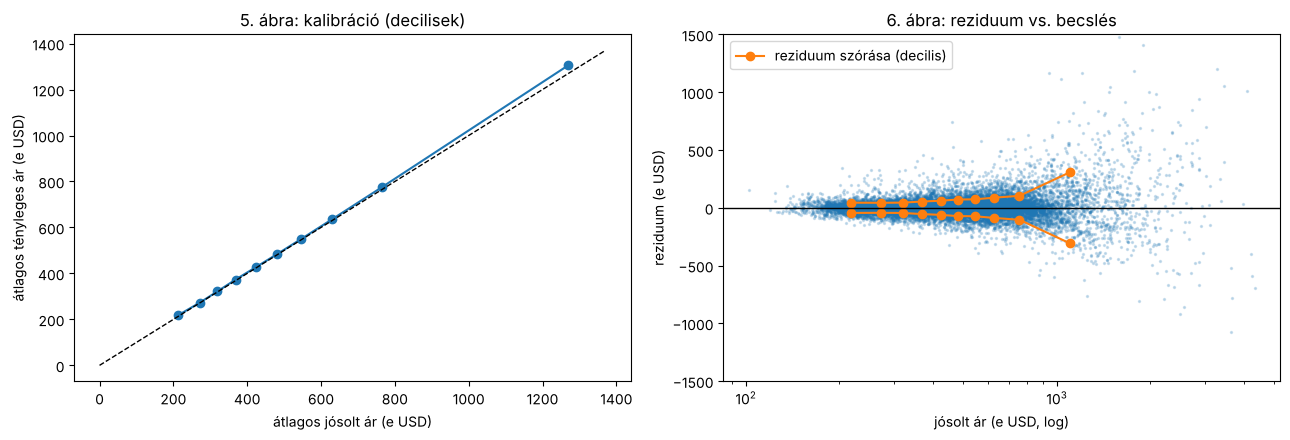

,jósolt,tényleges,tényleges/jósolt,USD-reziduum szórása (e),log-reziduum szórása
0,"212,000.0000","217,000.0000",1.0249,44.3000,0.2120
1,"272,000.0000","273,000.0000",1.0049,43.3000,0.1590
2,"319,000.0000","322,000.0000",1.0081,44.7000,0.1400
3,"369,000.0000","373,000.0000",1.0130,54.2000,0.1440
4,"423,000.0000","427,000.0000",1.0087,61.2000,0.1440
5,"480,000.0000","483,000.0000",1.0065,71.6000,0.1420
6,"546,000.0000","549,000.0000",1.0066,73.3000,0.1390
7,"631,000.0000","636,000.0000",1.0090,87.6000,0.1400
8,"764,000.0000","775,000.0000",1.0134,103.9000,0.1320
9,"1,270,000.0000","1,306,000.0000",1.0281,306.8000,0.1870


In [12]:
best = "XGBoost"
y = dev["price"].values
pred = OOF[best]
res_log = np.log(y) - np.log(pred)          # log-reziduum: + = alulbecslés, − = túlbecslés (arányosan)
res_usd = y - pred

# 7a. Kalibráció decilisenként (a JÓSLAT decilisei szerint)
dec = pd.qcut(pred, 10, labels=False)
calib = pd.DataFrame({"jósolt": pred, "tényleges": y}).groupby(dec).mean()
calib["tényleges/jósolt"] = calib["tényleges"] / calib["jósolt"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(calib["jósolt"] / 1000, calib["tényleges"] / 1000, "o-")
lim = [0, calib.values[:, :2].max() / 1000 * 1.05]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xlabel="átlagos jósolt ár (e USD)", ylabel="átlagos tényleges ár (e USD)", title="5. ábra: kalibráció (decilisek)")

# 7b. Reziduum vs. becsült érték
ax[1].scatter(pred / 1000, res_usd / 1000, s=2, alpha=0.2)
sd = pd.Series(res_usd).groupby(dec).std() / 1000
mid = pd.Series(pred).groupby(dec).median() / 1000
ax[1].plot(mid, sd, "C1o-", label="reziduum szórása (decilis)"); ax[1].plot(mid, -sd, "C1o-")
ax[1].axhline(0, color="k", lw=1); ax[1].set_xscale("log"); ax[1].set_ylim(-1500, 1500); ax[1].legend()
ax[1].set(xlabel="jósolt ár (e USD, log)", ylabel="reziduum (e USD)", title="6. ábra: reziduum vs. becslés")
plt.tight_layout(); plt.show()

tolcser = pd.DataFrame({"USD-reziduum szórása (e)": sd.round(1),
                        "log-reziduum szórása": pd.Series(res_log).groupby(dec).std().round(3)})
display(calib.assign(**{"jósolt": calib["jósolt"].round(-3), "tényleges": calib["tényleges"].round(-3)}).join(tolcser))

**7a. Kalibráció (5. ábra, táblázat):** a 2–9. decilisben a tényleges és a jósolt átlag eltérése 0,5–1,3%. A **legalsó decilisben 2,5%-kal** (212 helyett 217 ezer), a **legfelsőben 2,8%-kal** (1,270 helyett 1,306 millió) **alulbecsül**. A modell a széleket a közép felé húzza, ahogy az órán is (ott a felső decilis 7%-kal maradt alatta). *Mit tennék:* a drága szegmensnek külön jellemzők kellenének (pl. a kilátás minősége), de egy kis, következetes alulbecslés a bank szempontjából elfogadható irány.

**7b. Reziduum vs. becslés (6. ábra):** USD-ben erős **tölcsér**: a reziduum szórása 44 ezerről 307 ezerre nő (7×). Log-skálán viszont közel állandó (≈ 0,14), csak a két szélső decilisben magasabb (0,21 és 0,19). *Mit jelent:* a log-cél jó döntés volt, a hiba nagyjából arányos. A maradék gond a két szél, ahol bizonytalanabb a modell. Itt egy szélesebb bizonytalansági sávot adnék meg, nem egyetlen számot.

In [13]:
# 7c. Reziduum szegmensenként (átlagos log-reziduum: +0,05 ≈ 5%-os alulbecslés)
d = dev.assign(res=res_log, pred=pred)
d["jósolt ársáv"] = pd.cut(d["pred"], [0, 300e3, 450e3, 650e3, 1e6, 2e6, 1e9],
                            labels=["<300e", "300–450e", "450–650e", "650e–1M", "1–2M", ">2M"])
d["kor"] = pd.cut(d["age"], [-1, 10, 30, 60, 90, 200], labels=["0–10", "11–30", "31–60", "61–90", "90+"])
seg = lambda col: d.groupby(col, observed=True)["res"].agg(átlag="mean", szórás="std", db="size")
display(seg("jósolt ársáv"), seg("kor"))

z = seg("zipcode").query("db >= 50").sort_values("átlag")
print("Irányítószámok: az átlagos log-reziduum szórása a zipek között:", round(z["átlag"].std(), 4))
display(pd.concat([z.head(4), z.tail(4)]))

,átlag,szórás,db
jósolt ársáv,,,
<300e,-0.0018,0.1861,3488
300–450e,0.0004,0.1415,4905
450–650e,-0.0036,0.1408,4578
650e–1M,0.0023,0.1446,2790
1–2M,0.0112,0.1877,973
>2M,0.0181,0.2328,127


,átlag,szórás,db
kor,,,
0–10,0.0003,0.1133,2754
11–30,-0.0002,0.1243,3888
31–60,0.0006,0.1568,5635
61–90,-0.0010,0.1901,3172
90+,-0.0013,0.2077,1412


Irányítószámok: az átlagos log-reziduum szórása a zipek között: 0.0141


,átlag,szórás,db
zipcode,,,
98014,-0.0503,0.2527,101
98108,-0.0295,0.1514,148
98032,-0.0266,0.1800,104
98106,-0.0216,0.1921,246
98119,0.0232,0.1961,146
98136,0.0262,0.1659,194
98102,0.0276,0.2024,89
98010,0.0342,0.2436,79


**7c. Szegmensek:**
- **Jósolt ársáv:** az átlagos reziduum −0,4% és +1,8% között van. A 2 millió fölötti sávban (127 ház) a legnagyobb (+1,8%), a szórás is itt a legnagyobb (0,23). Ez ugyanaz, mint a kalibráció felső széle. (Szándékosan a *jósolt* ár szerint sávozok: a tényleges ár szerinti sávozás a regresszió a középhez jelenség miatt mindig „alulbecslést” mutatna a drága és „túlbecslést” az olcsó sávban.)
- **A ház kora:** torzítás nincs (minden korcsoportban |átlag| < 0,2%), de **a szórás a korral megduplázódik** (0–10 év: 0,113 → 90+ év: 0,208). A régi házak állapota nagyon különböző lehet (felújított villa vagy lepusztult ház), amit a `condition` és a `renovated` csak durván fog meg.
- **Irányítószám:** a zipek átlagos reziduumai között 0,014 a szórás, a szélsők 98014 (−5,0%, 101 eladás) és 98010 (+3,4%, 79 eladás), mindkettő vidéki, kis mintájú terület. *Mit tennék:* irányítószám-szinten nincs komoly torzítás, a `lat`/`long` és a `zip_num` ezt kezeli. Ha van hiányzó helyi információ, az finomabb, zipen belüli szinten lehet. Ezt nézi a térkép.

Korreláció a ház reziduuma és a 10 szomszéd átlagos reziduuma közt: 0.086 (véletlen sorrendben: 0.013)


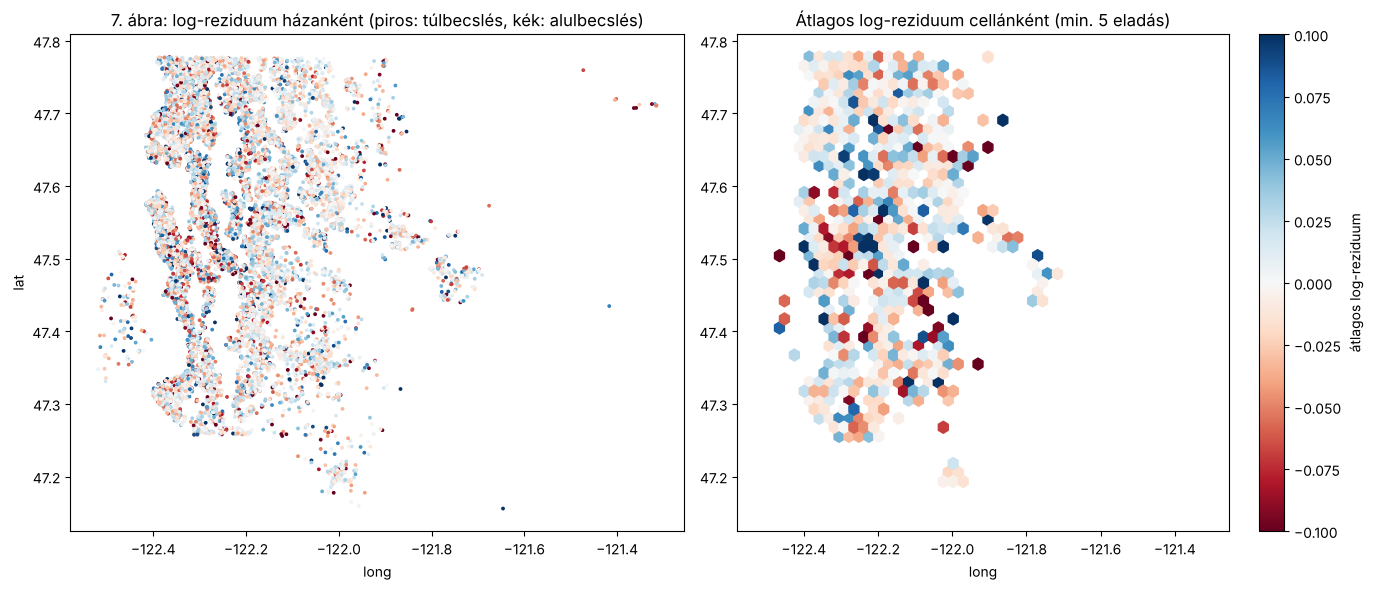

In [14]:
# 7d. Reziduum a térképen + térbeli autokorreláció: hasonlít-e egy ház hibája a szomszédaiéra?
def to_km(t):
    return np.c_[(t["lat"].values - 47.5) * 111.0, (t["long"].values + 122.2) * 111.0 * np.cos(np.radians(47.5))]

nn = NearestNeighbors(n_neighbors=11).fit(to_km(dev))
_, idx = nn.kneighbors(to_km(dev))
neigh_mean = res_log[idx[:, 1:]].mean(axis=1)                 # a 10 legközelebbi MÁSIK eladás átlagos reziduuma
r_space = np.corrcoef(res_log, neigh_mean)[0, 1]
perm = np.random.default_rng(SEED).permutation(res_log)        # összehasonlítás: ha a hibának nincs térbeli mintája
r_perm = np.corrcoef(perm, perm[idx[:, 1:]].mean(axis=1))[0, 1]
print(f"Korreláció a ház reziduuma és a 10 szomszéd átlagos reziduuma közt: {r_space:.3f} (véletlen sorrendben: {r_perm:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].scatter(dev["long"], dev["lat"], c=np.clip(res_log, -0.4, 0.4), cmap="RdBu", s=3)
ax[0].set(title="7. ábra: log-reziduum házanként (piros: túlbecslés, kék: alulbecslés)", xlabel="long", ylabel="lat")
hb = ax[1].hexbin(dev["long"], dev["lat"], C=res_log, reduce_C_function=np.mean, gridsize=45, cmap="RdBu",
                  vmin=-0.1, vmax=0.1, mincnt=5)
plt.colorbar(hb, ax=ax[1], label="átlagos log-reziduum")
ax[1].set(title="Átlagos log-reziduum cellánként (min. 5 eladás)", xlabel="long")
plt.tight_layout(); plt.show()

**7d. Reziduum a térképen (7. ábra):** szemre a kép zajos, nagy, egybefüggő színes régió nincs (a modell a nagy léptékű helyhatást a `lat`/`long`-ból megtanulta). A cellás térképen szétszórt sötétkék és sötétpiros cellák látszanak, ezért a szemnél a szám a megbízhatóbb mérce: egy ház reziduuma és a **10 legközelebbi másik eladás** átlagos reziduuma között **0,086** a korreláció, míg véletlen sorrendben 0,013. Kicsi, de valódi **térbeli mintázat**: a szomszédos házakat a modell ugyanabba az irányba téveszti.
*Mit tennék:* ebből jön a 8. pont **hipotézise**: a modellnek hiányzik a **helyi árszint**, az irányítószámnál finomabb felbontásban. Erre jó jellemző a „comps”, vagyis a közeli eladások átlagos ár/sqft-je.

In [15]:
# 7e. Lehetetlen jóslatok: negatív vagy a valaha látott legkisebb árnál kisebb ár
for name in ["XGBoost", "XGBoost, nyers cél", "Lineáris (Ridge)"]:
    pr = OOF[name]
    print(f"{name:20s}: negatív {int((pr < 0).sum()):3d} | 75 000 USD alatt (a legolcsóbb eladás) {int((pr < 75_000).sum()):3d} | "
          f"min {pr.min():>10,.0f} | max {pr.max():>12,.0f}")

XGBoost             : negatív   0 | 75 000 USD alatt (a legolcsóbb eladás)   0 | min    102,000 | max    4,331,145
XGBoost, nyers cél  : negatív   0 | 75 000 USD alatt (a legolcsóbb eladás)   0 | min    101,352 | max    5,157,723
Lineáris (Ridge)    : negatív   0 | 75 000 USD alatt (a legolcsóbb eladás)   0 | min     82,970 | max    6,034,592


**7e. Lehetetlen jóslatok:** egyik modell sem ad negatív árat, és 75 ezer USD (a legolcsóbb eladás) alatti jóslatot sem. A log-célú modell definíció szerint pozitív, de itt még a nyers célú XGBoost sem lép 0 alá, mert az árak messze vannak a nullától (az órai biciklis példában a 0 közeli éjszakai órák miatt ez másképp volt). A **felső vég** viszont összenyomott: az XGBoost legnagyobb jóslata 4,33 millió, miközben a valódi maximum 7,7 millió. A fa nem jósol a tanító levelek átlagánál nagyobbat. *Mit tennék:* a néhány extrém luxusháznál a jóslatot csak „alsó becslésként” kezelném.

## 8. Visszacsatolási kör: hipotézis → új jellemző → ugyanazok a foldok

**H1 (a 7d térképből):** a hibák térben korrelálnak (0,086), tehát hiányzik a **helyi árszint**. **Jellemző: „comps”** = a k = 20 legközelebbi eladás átlagos ár/sqft-je, és ennek szorzata a ház `sqft_living`-jével. **Szivárgás elleni szabályok:** (1) foldon belül, **csak a tanító részből** számolom; (2) a tanító soroknál **a ház saját eladása kimarad**, és ugyanannak a háznak a többi eladása is (különben a ház a saját árát látná, mint az órai központosított `roll3`); (3) a validációs és a teszt házak a tanítóban nem szerepelnek (csoportos vágás), így náluk ez automatikusan teljesül.

**H2 (a feladat tippje és a 7b/7c):** a fa nehezen tanulja meg azt, ami **két oszlopból számolt**, vagy **ferde irányban** hat, mert csak tengelyirányú küszöbökkel vág. **Geo jellemzők** (nem a célból számoltak, szivárgásmentesek): távolság Seattle és Bellevue belvárosától (km), elforgatott koordináták (15°, 30°, 45°, 60°), `living_ratio` = `sqft_living / sqft_living15` (nagyobb-e a ház a szomszédainál).

**Előzetes várakozás:** a comps a lineárisnak sokat segít, az XGBoostnak keveset, mert a fa a koordinátákból már sokat kiolvas. **Döntési szabály:** javulásnak csak azt nevezem, aminek a foldonkénti páros különbsége **minden foldon azonos előjelű, és az átlaga nagyobb a szórásánál**.

In [16]:
SEATTLE, BELLEVUE = (47.6062, -122.3321), (47.6101, -122.2015)

def km_from(t, pt):
    return np.hypot((t["lat"] - pt[0]) * 111.0, (t["long"] - pt[1]) * 111.0 * np.cos(np.radians(47.6)))

def add_geo(t):
    """1. jellemzőcsomag: a fának nehéz, mert két oszlopból számolt vagy ferde irányú (de NEM a célból számolt)."""
    t = t.copy()
    t["dist_seattle"] = km_from(t, SEATTLE)
    t["dist_bellevue"] = km_from(t, BELLEVUE)
    for a in (15, 30, 45, 60):                                  # elforgatott koordináták
        r = np.radians(a)
        t[f"rot{a}"] = t["lat"] * np.cos(r) + t["long"] * np.sin(r)
    t["living_ratio"] = t["sqft_living"] / t["sqft_living15"]   # nagyobb-e a ház, mint a szomszédoké?
    return t

GEO = ["dist_seattle", "dist_bellevue", "rot15", "rot30", "rot45", "rot60", "living_ratio"]
GEO_LIN = ["dist_seattle", "dist_bellevue", "living_ratio"]      # a lineárisnak a forgatás semmi újat nem ad (lineáris kombináció)
dev = add_geo(dev); test = add_geo(test)

In [17]:
def add_comps(train, other, k=20):
    """2. jellemző: „comps” = a k legközelebbi eladás átlagos ár/sqft-je (a koordináták alapján), × a ház sqft_living-je.
    SZIVÁRGÁSMENTES: a szomszédok MINDIG a tanító halmazból jönnek; a tanító soroknál a ház saját eladása(i) kimaradnak
    (önmaga és ugyanannak a háznak a másik eladása is), így a tanító és a validációs sorok jellemzője azonos módon készül."""
    train, other = train.copy(), other.copy()
    ppsf = (train["price"] / train["sqft_living"]).values
    hid = train["house_id"].values
    nn = NearestNeighbors(n_neighbors=k + 4).fit(to_km(train))
    _, idx = nn.kneighbors(to_km(train))
    keep = hid[idx] != hid[:, None]                                     # ugyanaz a ház (és önmaga) kiesik
    order = np.argsort(~keep, axis=1, kind="stable")[:, :k]             # az első k megengedett szomszéd
    assert keep[np.arange(len(idx))[:, None], order].all()
    train["comps_ppsf"] = ppsf[np.take_along_axis(idx, order, axis=1)].mean(axis=1)
    _, idx_o = nn.kneighbors(to_km(other), n_neighbors=k)               # a másik halmaz házai nincsenek a tanítóban
    other["comps_ppsf"] = ppsf[idx_o].mean(axis=1)
    for t in (train, other):
        t["comps_price"] = t["comps_ppsf"] * t["sqft_living"]
        t["log_comps_ppsf"] = np.log(t["comps_ppsf"])
        t["log_comps_price"] = np.log(t["comps_price"])
    return train, other

COMPS_TREE, COMPS_LIN = ["comps_ppsf", "comps_price"], ["log_comps_ppsf", "log_comps_price"]

# Ellenőrzés: a comps a tanító és a validációs sorokon azonos módon viselkedik-e?
a, b = add_comps(dev.iloc[FOLDS[0][0]], dev.iloc[FOLDS[0][1]])
print("comps_price ~ ár korreláció, tanító sorok (önmaga nélkül):", round(np.corrcoef(np.log(a['comps_price']), np.log(a['price']))[0, 1], 3))
print("comps_price ~ ár korreláció, validációs sorok:           ", round(np.corrcoef(np.log(b['comps_price']), np.log(b['price']))[0, 1], 3))

comps_price ~ ár korreláció, tanító sorok (önmaga nélkül): 0.905
comps_price ~ ár korreláció, validációs sorok:            0.914


In [18]:
# A CSAPDA bemutatása (a modellválasztásban NEM használjuk): a comps a teljes dev-en, a split ELŐTT,
# a ház saját árával együtt számolva. Ez a tipikus hiba: minden ház (a validációsak is) látja a saját árát.
_, i_all = NearestNeighbors(n_neighbors=20).fit(to_km(dev)).kneighbors(to_km(dev))   # az első szomszéd: önmaga
bad = dev.copy()
bad["comps_ppsf"] = (dev["price"] / dev["sqft_living"]).values[i_all].mean(axis=1)
bad["comps_price"] = bad["comps_ppsf"] * bad["sqft_living"]
bad["log_comps_ppsf"], bad["log_comps_price"] = np.log(bad["comps_ppsf"]), np.log(bad["comps_price"])
for name, mk in [("XGBoost + ROSSZ comps", lambda: LogModel(xgb(), TREE_FEATS + COMPS_TREE)),
                 ("Lineáris + ROSSZ comps", lambda: LogModel(Ridge(alpha=1.0), LIN_NUM + COMPS_LIN, ["zipcode"]))]:
    _, r = cv(mk, data=bad)
    print(f"{name:24s} CV-RMSLE {r['RMSLE'].mean():.4f}  CV-RMSE {r['RMSE'].mean() / 1000:.1f} e USD")

XGBoost + ROSSZ comps    CV-RMSLE 0.1521  CV-RMSE 112.5 e USD


Lineáris + ROSSZ comps   CV-RMSLE 0.1600  CV-RMSE 115.1 e USD


In [19]:
EXPS = {
    "XGBoost (alap)":            (lambda: LogModel(xgb(), TREE_FEATS), None),
    "XGBoost + geo":             (lambda: LogModel(xgb(), TREE_FEATS + GEO), None),
    "XGBoost + comps":           (lambda: LogModel(xgb(), TREE_FEATS + COMPS_TREE), add_comps),
    "XGBoost + geo + comps":     (lambda: LogModel(xgb(), TREE_FEATS + GEO + COMPS_TREE), add_comps),
    "Lineáris (alap)":           (lambda: LogModel(Ridge(alpha=1.0), LIN_NUM, ["zipcode"]), None),
    "Lineáris + geo":            (lambda: LogModel(Ridge(alpha=1.0), LIN_NUM + GEO_LIN, ["zipcode"]), None),
    "Lineáris + comps":          (lambda: LogModel(Ridge(alpha=1.0), LIN_NUM + COMPS_LIN, ["zipcode"]), add_comps),
    "Lineáris + geo + comps":    (lambda: LogModel(Ridge(alpha=1.0), LIN_NUM + GEO_LIN + COMPS_LIN, ["zipcode"]), add_comps),
}
for name, (mk, fe) in EXPS.items():
    if name not in RES:
        OOF[name], RES[name] = cv(mk, add_features=fe)
summary({k: RES[k] for k in EXPS})

,RMSE (e USD),MAE (e USD),WAPE,RMSLE,R2,jósolt/tényleges
XGBoost (alap),116.2 ± 15.6,59.9 ± 2.1,0.112 ± 0.003,0.156 ± 0.003,0.899 ± 0.014,0.986 ± 0.003
XGBoost + geo,115.6 ± 15.2,58.7 ± 1.8,0.109 ± 0.003,0.154 ± 0.004,0.900 ± 0.013,0.986 ± 0.003
XGBoost + comps,116.1 ± 16.8,59.2 ± 1.5,0.110 ± 0.002,0.155 ± 0.005,0.899 ± 0.016,0.987 ± 0.003
XGBoost + geo + comps,114.2 ± 15.8,58.3 ± 1.5,0.109 ± 0.002,0.153 ± 0.005,0.903 ± 0.014,0.987 ± 0.004
Lineáris (alap),126.8 ± 8.5,71.3 ± 2.0,0.133 ± 0.003,0.176 ± 0.004,0.879 ± 0.013,0.981 ± 0.002
Lineáris + geo,122.9 ± 8.4,69.6 ± 2.1,0.130 ± 0.003,0.173 ± 0.004,0.886 ± 0.015,0.982 ± 0.002
Lineáris + comps,119.5 ± 9.1,66.4 ± 1.8,0.124 ± 0.002,0.166 ± 0.004,0.893 ± 0.009,0.983 ± 0.002
Lineáris + geo + comps,116.9 ± 8.3,65.7 ± 2.0,0.123 ± 0.003,0.165 ± 0.004,0.897 ± 0.011,0.984 ± 0.003


In [20]:
# Páros különbség foldonként: (alap − új), pozitív = az új jobb. Javulásnak csak azt nevezem, ami minden foldon
# azonos előjelű ÉS az átlaga nagyobb, mint a foldok közti szórása.
def paired(base, new, metric):
    d = RES[base][metric] - RES[new][metric]
    scale = 1000 if metric == "RMSE" else 1
    return {"alap → új": f"{base} → {new}", "mutató": metric,
            "foldonként": " ".join(f"{v / scale:+.3f}" if scale == 1 else f"{v / scale:+.1f}" for v in d),
            "átlag ± szórás": f"{d.mean() / scale:+.4f} ± {d.std() / scale:.4f}" if scale == 1 else f"{d.mean() / scale:+.2f} ± {d.std() / scale:.2f} e USD",
            "minden foldon javít": bool((d > 0).all())}

pairs = [("XGBoost (alap)", "XGBoost + geo"), ("XGBoost (alap)", "XGBoost + comps"), ("XGBoost + comps", "XGBoost + geo + comps"),
         ("Lineáris (alap)", "Lineáris + geo"), ("Lineáris (alap)", "Lineáris + comps"), ("Lineáris + comps", "Lineáris + geo + comps")]
pd.DataFrame([paired(a, b, m) for a, b in pairs for m in ("RMSLE", "RMSE")])

,alap → új,mutató,foldonként,átlag ± szórás,minden foldon javít
0,XGBoost (alap) → XGBoost + geo,RMSLE,+0.003 +0.004 +0.001 +0.004 -0.000,+0.0022 ± 0.0018,False
1,XGBoost (alap) → XGBoost + geo,RMSE,+1.6 -0.7 +0.2 +2.8 -1.1,+0.60 ± 1.62 e USD,False
2,XGBoost (alap) → XGBoost + comps,RMSLE,+0.003 +0.002 -0.001 +0.002 -0.002,+0.0009 ± 0.0021,False
3,XGBoost (alap) → XGBoost + comps,RMSE,-1.1 +1.6 -2.8 +5.2 -2.1,+0.17 ± 3.25 e USD,False
4,XGBoost + comps → XGBoost + geo + comps,RMSLE,+0.002 +0.002 +0.001 +0.002 +0.003,+0.0020 ± 0.0004,True
5,XGBoost + comps → XGBoost + geo + comps,RMSE,+3.1 +0.6 +3.5 +0.1 +1.9,+1.84 ± 1.49 e USD,True
6,Lineáris (alap) → Lineáris + geo,RMSLE,+0.003 +0.002 +0.002 +0.002 +0.003,+0.0025 ± 0.0006,True
7,Lineáris (alap) → Lineáris + geo,RMSE,+7.1 +2.3 +3.5 +2.1 +4.4,+3.88 ± 2.05 e USD,True
8,Lineáris (alap) → Lineáris + comps,RMSLE,+0.012 +0.011 +0.007 +0.011 +0.009,+0.0099 ± 0.0020,True
9,Lineáris (alap) → Lineáris + comps,RMSE,+4.2 +9.3 +4.0 +9.1 +9.6,+7.25 ± 2.89 e USD,True


**Szivárgás-ellenőrzés:** a helyes comps és az ár korrelációja a tanító sorokon 0,905, a validációs sorokon 0,914, vagyis a jellemző a kettőn **azonos módon** viselkedik. A **ROSSZ változat** (a comps a teljes dev-en, a split előtt, a ház saját árával együtt) a CV-ben **jobbnak látszik**: XGBoost RMSLE 0,1521 (a helyes comps-szal 0,1549), lineáris 0,1600 (helyesen 0,1660). Az XGBoost esetében ez **még a végső nyertest (0,1528) is megverné**, vagyis a szivárgás nemcsak egy számot szépítene, hanem **a modellválasztást is megváltoztatná**. Élesben viszont egy új ház ára nem ismert, így ez a „javulás” eltűnne. Ugyanaz a jelenség, mint az órai központosított `roll3`-nál, csak kisebb, mert itt a saját ár a 20 szomszéd közül csak egy.

**Eredmények (páros különbség, alap − új, + = javulás):**
- **XGBoost + geo:** RMSLE **+0,0022 ± 0,0018**, 5 foldból 4-en javít. RMSE +0,6 ± 1,6 ezer, ami a zajon belül van. *Határeset:* az átlag épp nagyobb a szórásnál, de nem minden foldon javít, ezért önmagában **nem mondom valódi javulásnak**.
- **XGBoost + comps:** RMSLE +0,0009 ± 0,0021, RMSE +0,2 ± 3,3 ezer. **Nem segített.** A várakozás beigazolódott: a fa a helyi árszintet a koordinátákból már megtanulta.
- **XGBoost + comps → + geo:** RMSLE **+0,0020 ± 0,0004**, RMSE **+1,8 ± 1,5 ezer**, **mind az 5 foldon** javít. Ez **valódi, de kicsi javulás** (az RMSLE 1,3%-a). *Válasz a feladat kérdésére:* igen, van olyan jellemző, ami az XGBoostnak is segít. A geo csomag (távolság a belvárostól, elforgatott koordináták, méretarány) segít, de csak szerényen, és a comps mellett mérhető egyértelműen.
- **Lineáris:** a geo RMSLE-ben +0,0025 ± 0,0006, a comps **+0,0099 ± 0,0020** (5,6%), mindkettő minden foldon. Együtt az RMSE 126,8 → **116,9 ezer**. A lineáris tehát 4–5-ször többet nyer, mint a fa, ahogy a feladatleírás előzetes mérésében is. Ott a különbség nagyobb (203 → 128 ezer), mert az a lineáris modell irányítószám-dummyk nélkül indult.

**Ami nem működött vagy nyitva maradt:** a comps önmagában az XGBoostnak semmit nem hozott. A geo csomag elemeit (távolság, forgatás, méretarány) **nem választottam szét**, így nem tudom, melyik hozza a javulást. Ez lenne a következő lépés (ablation, mint az órán a lag-oknál).

In [21]:
# Újra a diagnosztika: csökkent-e a térbeli mintázat a legjobb új modellnél?
for name in ["XGBoost (alap)", "XGBoost + geo + comps", "XGBoost + comps"]:
    r = np.log(y) - np.log(OOF[name])
    print(f"{name:24s} térbeli autokorreláció: {np.corrcoef(r, r[idx[:, 1:]].mean(axis=1))[0, 1]:.3f} | "
          f"felső decilis tényleges/jósolt: {y[dec == 9].mean() / OOF[name][dec == 9].mean():.3f}")

XGBoost (alap)           térbeli autokorreláció: 0.086 | felső decilis tényleges/jósolt: 1.028
XGBoost + geo + comps    térbeli autokorreláció: -0.034 | felső decilis tényleges/jósolt: 1.024
XGBoost + comps          térbeli autokorreláció: -0.001 | felső decilis tényleges/jósolt: 1.024


**Újra a diagnosztika:** a térbeli autokorreláció 0,086-ról **−0,001**-re (comps) és −0,034-re (geo + comps) esett. **A hipotézis a hiba szerkezetében beigazolódott**: a helyi mintázat eltűnt. Az XGBoost hibája viszont alig csökkent, vagyis ez a mintázat kicsi része volt a teljes hibának. A felső decilis alulbecslése (1,028 → 1,024) gyakorlatilag maradt: a luxusházak összenyomása nem helyi árszint-probléma.

## 9. Záró teszt: egyszer

A szabály előre rögzített (1. pont): **a legkisebb CV-RMSLE nyer.** A nyertes, a naiv szabály, a lineáris alapmodell és a lineáris + új jellemzők a **teljes fejlesztési adaton** tanulnak, és a teszten egyszer jósolnak. A teszt-házak comps jellemzője a fejlesztési adatból (tehát csak **korábbi** eladásokból) számolódik, ez élesben is így lenne.

In [22]:
# Az előre rögzített szabály: a legkisebb CV-RMSLE nyer (a jelöltek: minden fenti CV-ben mért modell)
cand = pd.Series({k: v["RMSLE"].mean() for k, v in RES.items()}).sort_values()
print(cand.round(4).to_string())
WINNER = cand.index[0]
print("\nNyertes:", WINNER)

XGBoost + geo + comps    0.1528
XGBoost + geo            0.1535
XGBoost + comps          0.1549
XGBoost                  0.1558
XGBoost (alap)           0.1558
XGBoost + smearing       0.1558
XGBoost, nyers cél       0.1585
Lineáris + geo + comps   0.1653
Lineáris + comps         0.1660
Random Forest            0.1720
Lineáris + geo           0.1735
Lineáris (Ridge)         0.1760
Lineáris (alap)          0.1760
Lineáris + smearing      0.1766
Döntési fa               0.2148
Zip-medián               0.3660
Átlag                    0.5487

Nyertes: XGBoost + geo + comps


In [23]:
# A záró teszt EGYSZER: minden modell a teljes dev-en tanul, a teszten jósol
ALL = {**{k: (v, None) for k, v in MODELS.items()}, **{k: (v, None) for k, v in extra.items()}, **EXPS}
FINAL = {
    "Zip-medián (naiv)": (MODELS["Zip-medián"], None),
    "Lineáris (alap)":   (EXPS["Lineáris (alap)"][0], None),
    WINNER:              ALL[WINNER],
}
if "Lineáris + geo + comps" != WINNER:
    FINAL["Lineáris + geo + comps"] = EXPS["Lineáris + geo + comps"]

TEST_PRED = {}
for name, (mk, fe) in FINAL.items():
    a, b = (fe(dev, test) if fe else (dev, test))
    TEST_PRED[name] = mk().fit(a, a["price"].values).predict(b)
yt = test["price"].values
test_tab = pd.DataFrame({n: metrics(yt, p) for n, p in TEST_PRED.items()}).T
cv_tab = pd.DataFrame({n: RES[{"Zip-medián (naiv)": "Zip-medián"}.get(n, n)].mean() for n in TEST_PRED}).T
pd.concat({"teszt": test_tab, "CV (dev)": cv_tab}, axis=1).round(3)

teszt                                    \
                               RMSE          MAE   WAPE  RMSLE     R2   
Zip-medián (naiv)      302,092.7940 158,677.8600 0.2850 0.3680 0.3410   
Lineáris (alap)        143,996.3010  80,591.7280 0.1450 0.1920 0.8500   
XGBoost + geo + comps  121,463.0240  67,218.6520 0.1210 0.1680 0.8930   
Lineáris + geo + comps 132,335.9820  74,915.3750 0.1350 0.1800 0.8730   

                                            CV (dev)                      \
                       jósolt/tényleges         RMSE          MAE   WAPE   
Zip-medián (naiv)                0.8540 291,783.0490 154,944.0060 0.2890   
Lineáris (alap)                  0.9290 126,751.5070  71,251.8560 0.1330   
XGBoost + geo + comps            0.9470 114,212.8750  58,334.5860 0.1090   
Lineáris + geo + comps           0.9300 116,910.5590  65,734.1070 0.1230   

                                                       
                        RMSLE     R2 jósolt/tényleges  
Zip-medián (naiv)      0.3660 0.3630           0.8980  
Lineáris (alap)        0.1760 0.8790           0.9810  
XGBoost + geo + comps  0.1530 0.9030           0.9870  
Lineáris + geo + comps 0.1650 0.8970           0.9840

In [24]:
# Bizonytalanság: bootstrap HÁZANKÉNT (egy ház összes teszt-eladása együtt kerül be vagy ki), 2000 újramintázás
groups = test.groupby("house_id").indices
gl = list(groups.values())
B, rng_b = 2000, np.random.default_rng(SEED)
names = list(TEST_PRED)
boot = {n: {"RMSE": [], "RMSLE": []} for n in names}
for _ in range(B):
    ix = np.concatenate([gl[i] for i in rng_b.integers(0, len(gl), len(gl))])
    for n in names:
        mm = metrics(yt[ix], TEST_PRED[n][ix])
        boot[n]["RMSE"].append(mm["RMSE"]); boot[n]["RMSLE"].append(mm["RMSLE"])

def ci(v, scale=1):
    v = np.asarray(v) / scale; return f"{np.mean(v):,.3f} [{np.percentile(v, 2.5):,.3f}; {np.percentile(v, 97.5):,.3f}]"

rows = {n: {"RMSE (e USD) [95% CI]": ci(boot[n]["RMSE"], 1000), "RMSLE [95% CI]": ci(boot[n]["RMSLE"])} for n in names}
for base in [n for n in names if n != WINNER]:
    rows[f"{base} − {WINNER}"] = {
        "RMSE (e USD) [95% CI]": ci(np.subtract(boot[base]["RMSE"], boot[WINNER]["RMSE"]), 1000),
        "RMSLE [95% CI]": ci(np.subtract(boot[base]["RMSLE"], boot[WINNER]["RMSLE"]))}
pd.DataFrame(rows).T

,RMSE (e USD) [95% CI],RMSLE [95% CI]
Zip-medián (naiv),301.454 [275.853; 330.628],0.368 [0.357; 0.379]
Lineáris (alap),143.793 [131.351; 157.634],0.192 [0.187; 0.197]
XGBoost + geo + comps,121.255 [110.059; 133.444],0.168 [0.163; 0.174]
Lineáris + geo + comps,132.145 [121.241; 144.638],0.180 [0.175; 0.185]
Zip-medián (naiv) − XGBoost + geo + comps,180.199 [161.815; 199.378],0.200 [0.190; 0.210]
Lineáris (alap) − XGBoost + geo + comps,22.538 [12.696; 31.248],0.024 [0.020; 0.027]
Lineáris + geo + comps − XGBoost + geo + comps,10.890 [3.554; 17.685],0.011 [0.008; 0.014]


In [25]:
# Sodródás a teszten: követi-e a modell a tavaszi árszintet? (havonta: Σ jósolt / Σ tényleges)
t = test.assign(p=TEST_PRED[WINNER], hó=test["date"].dt.to_period("M"))
print("Teszt, havonta jósolt/tényleges összeg:", t.groupby("hó").apply(lambda g: round(g["p"].sum() / g["price"].sum(), 3), include_groups=False).to_dict())
print("CV-ben ugyanez a dev-en:", round(OOF[WINNER].sum() / y.sum(), 3))

Teszt, havonta jósolt/tényleges összeg: {Period('2015-03', 'M'): 0.963, Period('2015-04', 'M'): 0.939, Period('2015-05', 'M'): 0.924}
CV-ben ugyanez a dev-en: 0.987


**Eredmény:**
- **Nyertes:** XGBoost + geo + comps (CV-RMSLE 0,1528). Teszt-RMSLE: **0,168 [0,163; 0,174]**, RMSE **121,3 ezer [110,1; 133,4]** (95%-os bootstrap-intervallum házanként, 2000 újramintázás).
- **Az alapokhoz képest** (páros bootstrap-különbség, mind a 0 felett):
  - a naiv zip-mediánnál RMSLE-ben 0,200-zal, RMSE-ben 180 ezerrel jobb;
  - a lineáris alapmodellnél RMSLE-ben **0,024 [0,020; 0,027]**, RMSE-ben **22,5 ezer [12,7; 31,2]** a javulás;
  - a lineáris + geo + comps modellnél is jobb: 0,011 [0,008; 0,014].
- **A teszt rosszabb, mint a CV** (RMSLE 0,153 → 0,168, RMSE 114,2 → 121,3 ezer). **Az ok a sodródás:** a jósolt/tényleges arány a CV-ben 0,987, a teszten **0,947**, és havonta romlik (márc. 0,963, ápr. 0,939, máj. 0,924). A tavaszi árszint magasabb, mint a tanító időszak vége (téli mélypont, 4. ábra). A fa a `t_days`-t nem tudja a tanító tartományán túl vinni. A lineáris alapmodell is alulbecsül (0,929): ő extrapolál, de a dev nyár → tél **csökkenő** trendjét vetíti előre. Más okból, de mindkét modell téved.
- **Tanulság:** a csoportos véletlen CV (és az órai véletlen vágás) jobb képet fest, mint ami a jövőre igaz. A modell sorrendje a teszten is ugyanaz, a szint viszont nem. A bank szempontjából az alulbecslés a „biztonságos” irány, de 5–8%-os rendszeres eltérés mellett újratanítás vagy szezonális korrekció kellene.

## 10. Korlátok

1. A modell 2014 májusa és 2015 februárja között tanult, ezért a tavaszi főszezont **rendszeresen, havonta növekvő mértékben (3,7% → 7,6%) alulbecsüli**, amit élesben havi újratanítással vagy több évnyi adatból tanult szezonális jellemzővel kellene kezelni.
2. A fejlesztési CV **házanként véletlenszerű volt, nem időrendi**, és a hiperparamétereket nem hangoltam, ezért a CV-számok optimisták (RMSLE 0,153 a teszt 0,168-ával szemben), és a comps a tanító soroknál időben későbbi eladásokat is felhasználhatott.
3. A felső vég összenyomott (a legnagyobb jóslat 4,3 millió a 7,7 milliós maximummal szemben), az XGBoost 1,4%-os log-visszaalakítási torzítását nem korrigáltam pontosan, és a 13 „0 hálószobás”, valószínűleg hiányzó adatú sort nem kezeltem külön.